In [1]:
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parents[1])
print("Working directory:", Path.cwd())

sys.path.append("ml/training")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from train_model import run_experiment

print("xgboost", xgboost.__version__)

Working directory: C:\Users\shame\OneDrive\Desktop\EcoPackAI
xgboost 2.1.0


In [2]:
materials = pd.read_csv("data/processed/materials.csv")

TARGET = "co2_emission_per_kg"
train_df, test_df = train_test_split(materials, test_size=0.2, random_state=42)

print("Train:", train_df.shape, "Test:", test_df.shape)
print(materials.groupby("material_type")[TARGET].agg(["min", "mean", "max", "count"]).round(3))

Train: (322, 23) Test: (81, 23)
                  min   mean   max  count
material_type                            
Cardboard        0.47  0.510  0.55    139
Paper/Bio-Based  0.28  0.301  0.33     37
Plastic          1.35  1.480  1.64    198
Steel            2.71  3.028  3.25     29


In [3]:
preprocessor = joblib.load("models/preprocessing/preprocessing_pipeline.pkl")
feature_names = preprocessor.get_feature_names_out()

leaky = [f for f in feature_names if "co2_emission_per_kg" in f or "cost_per_unit" in f]
print("Number of features:", len(feature_names))
print("Leaky features found:", leaky)
assert not leaky, "Target leakage detected!"

X_train = preprocessor.transform(train_df)
X_test = preprocessor.transform(test_df)
y_train = train_df[TARGET]
y_test = test_df[TARGET]
print("X_train:", X_train.shape, "X_test:", X_test.shape)

Number of features: 31
Leaky features found: []
X_train: (322, 31) X_test: (81, 31)


round   1: train RMSE 0.6974   validation RMSE 0.7474
round  50: train RMSE 0.1783   validation RMSE 0.1945
round 100: train RMSE 0.0656   validation RMSE 0.0908
round 200: train RMSE 0.0373   validation RMSE 0.0839
round 300: train RMSE 0.0301   validation RMSE 0.0846
round 400: train RMSE 0.0255   validation RMSE 0.0853
round 500: train RMSE 0.0215   validation RMSE 0.0852
Lowest validation RMSE 0.0827 at round 148


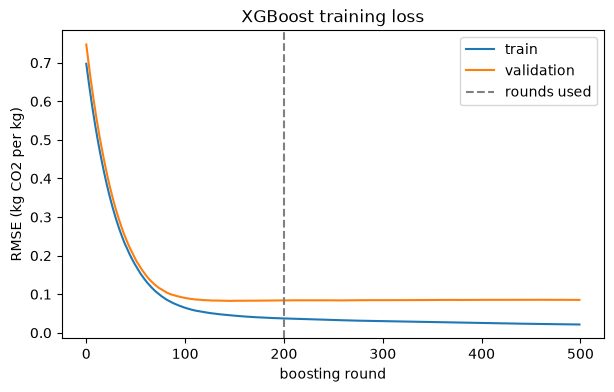

In [4]:
XGB_PARAMS = {
    "objective": "reg:squarederror",
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.5,
    "random_state": 42,
    "n_jobs": -1,
}

# Hold out 20% of the TRAINING rows as a validation set to watch the loss.
# The test set is never used here.
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

# Train 500 rounds here on purpose, to see the whole curve beyond the 200 we use
monitor = XGBRegressor(**{**XGB_PARAMS, "n_estimators": 500}, eval_metric="rmse")
monitor.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)

history = monitor.evals_result()
train_rmse = history["validation_0"]["rmse"]
val_rmse = history["validation_1"]["rmse"]

for n in [1, 50, 100, 200, 300, 400, 500]:
    print(f"round {n:>3}: train RMSE {train_rmse[n - 1]:.4f}   validation RMSE {val_rmse[n - 1]:.4f}")

best_round = int(np.argmin(val_rmse)) + 1
print(f"Lowest validation RMSE {min(val_rmse):.4f} at round {best_round}")

plt.figure(figsize=(7, 4))
plt.plot(train_rmse, label="train")
plt.plot(val_rmse, label="validation")
plt.axvline(XGB_PARAMS["n_estimators"], color="grey", linestyle="--", label="rounds used")
plt.xlabel("boosting round")
plt.ylabel("RMSE (kg CO2 per kg)")
plt.title("XGBoost training loss")
plt.legend()
plt.show()

In [5]:
xgb = XGBRegressor(**XGB_PARAMS)

version = run_experiment(
    model=xgb,
    model_name="XGBRegressor",
    target_name=TARGET,
    X_train=X_train, y_train=y_train,
    X_test=X_test, y_test=y_test,
    dataset_version="v1",
    feature_set_version="v1",
    notes="Production CO2 model, initial hyperparameters (200 rounds, depth 3, lr 0.03, colsample 0.5), random_state=42.",
)

Experiment logged: XGBRegressor__co2_emission_per_kg__v1__20261004_185626
  Model saved to: ml\models\XGBRegressor_co2_emission_per_kg_v1.pkl
  Metadata saved to: ml\experiments\metadata\XGBRegressor__co2_emission_per_kg__v1__20261004_185626.json
  Test R2: 0.9938, Test MAE: 0.0358, Test RMSE: 0.0537


In [6]:
cv = cross_validate(
    XGBRegressor(**XGB_PARAMS), X_train, y_train, cv=5,
    scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
)
fold_scores = {
    "MAE": -cv["test_neg_mean_absolute_error"],
    "RMSE": -cv["test_neg_root_mean_squared_error"],
    "R2": cv["test_r2"],
}

y_pred = xgb.predict(X_test)
test_scores = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "RMSE": root_mean_squared_error(y_test, y_pred),
    "R2": r2_score(y_test, y_pred),
}

for metric in ["MAE", "RMSE", "R2"]:
    print(f"{metric:<5} folds: {np.round(fold_scores[metric], 4)}  "
          f"CV mean: {fold_scores[metric].mean():.4f}  Test: {test_scores[metric]:.4f}")

MAE   folds: [0.0458 0.0465 0.0581 0.0543 0.0398]  CV mean: 0.0489  Test: 0.0358
RMSE  folds: [0.0758 0.0819 0.0882 0.1112 0.0594]  CV mean: 0.0833  Test: 0.0537
R2    folds: [0.9856 0.9892 0.9846 0.9806 0.9922]  CV mean: 0.9864  Test: 0.9938


In [7]:
baseline = pd.read_csv("ml/metrics/baseline_metrics.csv")
dt = baseline[baseline["model"] == "DecisionTreeRegressor"].set_index("metric")

type_means = train_df.groupby("material_type")[TARGET].mean()
lookup_pred = test_df["material_type"].map(type_means)
lookup_scores = {
    "MAE": mean_absolute_error(y_test, lookup_pred),
    "RMSE": root_mean_squared_error(y_test, lookup_pred),
    "R2": r2_score(y_test, lookup_pred),
}

comparison = pd.DataFrame({
    "Material-type average": lookup_scores,
    "Decision Tree (baseline)": dt["test_value"],
    "XGBoost": test_scores,
}).T.round(4)
comparison

,MAE,RMSE,R2
Material-type average,0.0333,0.0503,0.9945
Decision Tree (baseline),0.0507,0.0780,0.9869
XGBoost,0.0358,0.0537,0.9938


In [8]:
before, after = dt.loc["RMSE", "test_value"], test_scores["RMSE"]
print(f"RMSE vs Decision Tree baseline: {before:.4f} -> {after:.4f}  ({(before - after) / before:.0%} lower)")
print("RMSE improves over baseline:", after < before)

errors = test_df.assign(predicted=y_pred, abs_error=(y_test - y_pred).abs())
errors.groupby("material_type")["abs_error"].agg(["mean", "max", "count"]).round(4)

RMSE vs Decision Tree baseline: 0.0780 -> 0.0537  (31% lower)
RMSE improves over baseline: True


,mean,max,count
material_type,,,
Cardboard,0.0147,0.0871,33
Paper/Bio-Based,0.0166,0.0292,6
Plastic,0.0544,0.1496,37
Steel,0.0611,0.2270,5


In [9]:
os.makedirs("ml/reports", exist_ok=True)

feature_importance = (
    pd.DataFrame({
        "model": "XGBRegressor",
        "target": TARGET,
        "feature": feature_names,
        "importance_gain": xgb.feature_importances_,
    })
    .sort_values("importance_gain", ascending=False)
    .reset_index(drop=True)
)
feature_importance["rank"] = feature_importance.index + 1
feature_importance.to_csv("ml/reports/feature_importance.csv", index=False)
feature_importance.head(10).round(4)

,model,target,feature,importance_gain,rank
0,XGBRegressor,co2_emission_per_kg,num__moisture_resistance_score,0.2040,1
1,XGBRegressor,co2_emission_per_kg,nom__material_type_Plastic,0.1988,2
2,XGBRegressor,co2_emission_per_kg,num__end_of_life_disposal_percent,0.1608,3
3,XGBRegressor,co2_emission_per_kg,num__biodegradation_time_days,0.1098,4
4,XGBRegressor,co2_emission_per_kg,nom__material_type_Steel,0.0916,5
5,XGBRegressor,co2_emission_per_kg,num__load_handling_score,0.0661,6
6,XGBRegressor,co2_emission_per_kg,num__thermal_resistance_score,0.0465,7
7,XGBRegressor,co2_emission_per_kg,num__recycled_content_percent,0.0358,8
8,XGBRegressor,co2_emission_per_kg,num__carbon_footprint_kg_co2_per_unit,0.0241,9
9,XGBRegressor,co2_emission_per_kg,num__annual_usage_units,0.0241,10


In [10]:
xgb_co2_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", xgb),
])

joblib.dump(xgb_co2_pipeline, "ml/models/xgb_co2.joblib")

reloaded = joblib.load("ml/models/xgb_co2.joblib")
raw_pred = reloaded.predict(test_df)
print("Reloaded predictions match:", np.allclose(raw_pred, y_pred))
print(test_df[["material_id", "material_type", TARGET]].head(3).assign(predicted=raw_pred[:3].round(3)))

Reloaded predictions match: True
    material_id material_type  co2_emission_per_kg  predicted
70     MAT_0071       Plastic                 1.42      1.512
281    MAT_0282       Plastic                 1.55      1.467
283    MAT_0284       Plastic                 1.52      1.503


In [11]:
rows = []
for metric in ["MAE", "RMSE", "R2"]:
    row = {"model": "XGBRegressor", "target": TARGET, "metric": metric}
    row.update({f"fold_{i + 1}": round(v, 8) for i, v in enumerate(fold_scores[metric])})
    row["cv_mean"] = round(fold_scores[metric].mean(), 8)
    row["test_value"] = round(test_scores[metric], 4)
    rows.append(row)

co2_metrics = pd.DataFrame(rows)
co2_metrics.to_csv("ml/metrics/co2_metrics.csv", index=False)
co2_metrics

,model,target,metric,fold_1,fold_2,fold_3,fold_4,fold_5,cv_mean,test_value
0,XGBRegressor,co2_emission_per_kg,MAE,0.045796,0.046506,0.058113,0.054262,0.039814,0.048898,0.0358
1,XGBRegressor,co2_emission_per_kg,RMSE,0.075802,0.081905,0.088208,0.111185,0.059418,0.083304,0.0537
2,XGBRegressor,co2_emission_per_kg,R2,0.985576,0.989227,0.984551,0.980626,0.992233,0.986443,0.9938
